## Problem
**NorthLine Commerce wants to flag orders that might run into delivery problems early enough for support staff to help.**

- This is a binary classification problem.
- **Prediction time = the moment an order is dispatched.** I can only use what is known at that moment.
- **Label:** `delivery_exception_7d`. **Positive class = 1**, meaning a delivery problem was recorded in the first seven days.
- **Benefit:** support time goes to the orders most likely to go wrong.
- **False positive** = a healthy order gets flagged, so a support check is wasted.
- **False negative** = a problem order is missed, so we lose the chance to help (late parcel, refund, support ticket).
- **Cost assumption:** the file has no costs, so I *assume* a miss costs **5×** a wasted check and that support can review **20%** of orders. These only decide the alert cutoff (Cell 20).

Core problem: **At dispatch, will this order have a recorded delivery problem in the next seven days?**

**Roadmap:** audit (Cells 4–5) → split (Cell 7) → clean and engineer features (Cells 9–14) → baseline vs forest and tuning (Cells 16–18) → alert cutoff (Cell 20) → one test evaluation (Cells 22–24) → errors (Cells 26–27) → data-quality log (Cell 29).

In [1]:
import os, sys, json, time, warnings
from datetime import timedelta
from itertools import product
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyspark, sklearn
from IPython.display import display
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import Imputer, OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession, functions as F
from sklearn.metrics import (ConfusionMatrixDisplay, auc, average_precision_score,
                             confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)

# ---------------------------------------------------------------- configuration
CSV_PATH = Path("Dataset.csv")              # keep Dataset.csv in the same folder as this notebook
DATE = "dispatch_date"
TARGET = "delivery_exception_7d"
SEED = 4133
QUICK = os.environ.get("NL_QUICK") == "1"   # NL_QUICK=1 runs tiny grids as a smoke test; leave unset for the real run
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # figures and tables used by the report are written here
COST_FP, COST_FN = 1.0, 5.0                 # ASSUMPTION: a missed exception costs 5x an unnecessary check
CAPACITY = 0.20                             # ASSUMPTION: support can review the top 20% of orders
N_BOOT = 50 if QUICK else 1000
if not CSV_PATH.exists():
    raise FileNotFoundError(f"Put Dataset.csv next to the notebook (looked for {CSV_PATH.resolve()}).")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

spark = (
    SparkSession.builder.master("local[*]")
    .appName("NorthLine")
    .config("spark.ui.enabled", "false")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.shuffle.partitions", 8)
    .config("spark.sql.adaptive.enabled", "false")   # fixed partitioning -> repeatable results on any machine
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
raw = spark.read.csv(str(CSV_PATH), header=True).cache()

RUN = {"versions": {"python": sys.version.split()[0], "pyspark": pyspark.__version__, "pandas": pd.__version__,
                    "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                    "matplotlib": matplotlib.__version__}, "quick_mode": QUICK, "seed": SEED,
       "cost_fp": COST_FP, "cost_fn": COST_FN, "capacity": CAPACITY}
T0 = time.time()

def save(df, name):
    df.to_csv(OUT / f"{name}.csv")
    return df

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=35967 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up _JAVA_OPTIONS: -XX:+UnlockDiagnosticVMOptions -XX:DisableIntrinsic=_base64_encodeBlock,_base64_decodeBlock
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.ne

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/17 22:41:43 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/17 22:41:43 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/17 22:41:44 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. What’s in the CSV?

Each row describes a NorthLine order. The file is synthetic and includes details we have when the order ships, like the carrier and parcel weight, plus outcomes we learn later.

- `delivery_exception_7d = 1` means a problem was recorded in the first seven days.
- `delivery_exception_7d = 0` means no problem was recorded in that window.

I first read every column as text so I can see bad dates, odd values and blanks as they appear in the file.

- **Cell 4** shows the size (**121,150 rows × 33 columns**), the schema and the blanks per column.
- **Cell 5** cleans up the rows themselves: **500** exact duplicates (I keep one copy), **650** order IDs that appear twice with different values (I drop both copies, **1,300 rows**, because there is no trusted version) and **548** rows with an unusable dispatch date (`2025/13/09` has month 13, `not_a_date`, or blank).

**After those checks, 118,802 orders are usable.**

In [2]:
raw_count = raw.count()
print(f"{raw_count:,} rows x {len(raw.columns)} columns")
raw.printSchema()

missing = raw.agg(*[
    F.count_if(F.col(c).isNull() | (F.trim(c) == "")).alias(c) for c in raw.columns
]).first()
blank_counts = pd.Series(missing.asDict(), name="blank rows").sort_values(ascending=False)
display(blank_counts[blank_counts > 0])
print("Raw label values (text):")
print(raw.groupBy(TARGET).count().orderBy(TARGET).toPandas().to_string(index=False))
RUN["raw_rows"], RUN["raw_columns"] = raw_count, len(raw.columns)

121,150 rows x 33 columns
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- merchant_id: string (nullable = true)
 |-- dispatch_date: string (nullable = true)
 |-- warehouse_id: string (nullable = true)
 |-- destination_province: string (nullable = true)
 |-- destination_zone: string (nullable = true)
 |-- carrier: string (nullable = true)
 |-- shipping_service: string (nullable = true)
 |-- order_channel: string (nullable = true)
 |-- device_type: string (nullable = true)
 |-- product_category: string (nullable = true)
 |-- order_value_cad: string (nullable = true)
 |-- parcel_weight_kg: string (nullable = true)
 |-- item_count: string (nullable = true)
 |-- shipping_distance_km: string (nullable = true)
 |-- customer_tenure_months: string (nullable = true)
 |-- prior_order_count: string (nullable = true)
 |-- prior_exception_count: string (nullable = true)
 |-- address_quality_score: string (nullable = true)
 |-- warehouse_backlog_at_dispatc

address_quality_score           9364
weather_forecast_at_dispatch    5518
parcel_weight_kg                4420
customer_tenure_months          3224
shipping_distance_km            3077
order_channel                   2730
inventory_status_at_dispatch    2166
destination_zone                2052
order_value_cad                 1728
dispatch_date                    200
Name: blank rows, dtype: int64

Raw label values (text):


delivery_exception_7d  count
                    0 104586
                    1  16564


In [3]:
dq_rows = []
def log_issue(problem, evidence, action, rationale, effect, scope, count):
    dq_rows.append({"Problem": problem, "Detection evidence": evidence, "Action": action, "Rationale": rationale,
                    "Potential effect on results": effect, "Scope": scope, "Count": count})

distinct = raw.dropDuplicates().cache()
distinct_count = distinct.count()
conflicts = distinct.groupBy("order_id").count().where("count > 1").cache()
conflict_ids, conflict_rows = conflicts.agg(F.count("*"), F.sum("count")).first()
conflict_rows = conflict_rows or 0

conflict_fields = [c for c in raw.columns if c != "order_id"]
versions = distinct.join(conflicts, "order_id", "left_semi").groupBy("order_id").agg(
    *[F.countDistinct(F.struct(c)).alias(c) for c in conflict_fields]
)
changes = versions.agg(*[F.count_if(F.col(c) > 1).alias(c) for c in conflict_fields]).first().asDict()
changes = {c: n for c, n in changes.items() if n}
print("Orders with conflicting values by column:", changes)
conflict_label_rate = distinct.join(conflicts, "order_id", "left_semi").agg(
    F.avg(F.col(TARGET).try_cast("double"))).first()[0]

# dispatch dates that do not look like YYYY-MM-DD (evidence for the data-quality log)
date_text = F.coalesce(F.trim(F.col(DATE)), F.lit(""))
bad_date_counts = (distinct.join(conflicts, "order_id", "left_anti")
                   .where(~date_text.rlike(r"^\d{4}-\d{2}-\d{2}$"))
                   .groupBy(date_text.alias("value")).count().orderBy(F.desc("count")).toPandas())
print("Dispatch-date strings that are not YYYY-MM-DD:")
print(bad_date_counts.to_string(index=False))

unique = distinct.join(conflicts, "order_id", "left_anti").withColumns({
    DATE: F.when(F.trim(DATE).rlike(r"^\d{4}-\d{2}-\d{2}$"), F.trim(DATE).try_cast("date")),
    "label": F.col(TARGET).try_cast("double"),
})
valid_id = F.col("order_id").isNotNull() & (F.trim("order_id") != "")
valid_label = F.coalesce(F.col("label").isin(0, 1), F.lit(False))
bad_keys = unique.agg(
    F.count_if(~valid_id).alias("unusable order ID"),
    F.count_if(F.col(DATE).isNull()).alias("unusable dispatch date"),
    F.count_if(~valid_label).alias("unusable label"),
).first().asDict()
print("After deduplication:", bad_keys)

eligible = unique.where(valid_id & F.col(DATE).isNotNull() & valid_label).cache()
eligible_count = eligible.count()
eligible_rate = eligible.agg(F.avg("label")).first()[0]
print(f"Eligible orders: {eligible_count:,}  (exception rate {eligible_rate:.2%})")

bad_txt = "; ".join(f"'{v}' x{n}" for v, n in zip(bad_date_counts["value"], bad_date_counts["count"]))
log_issue("Exact duplicate rows",
          f"{raw_count:,} rows vs {distinct_count:,} after dropDuplicates()",
          "Keep one copy of each exact duplicate.",
          "The same order must not be counted twice or appear in two splits.",
          "Negligible: identical rows carry no extra information.", "Whole file", raw_count - distinct_count)
log_issue("Same order_id with conflicting values",
          f"{conflict_ids} order IDs have two different versions; they differ only in {changes}. "
          f"Exception rate of the conflicting rows {conflict_label_rate:.1%} vs {eligible_rate:.1%} overall.",
          f"Drop all {conflict_rows:,} rows of these orders.",
          "There is no authoritative copy; choosing one would inject arbitrary noise into two model inputs.",
          "Loses about 1% of orders. The exception rate of the dropped orders is close to the overall rate, so little bias is expected.",
          "Whole file", int(conflict_ids))
log_issue("Unusable dispatch date",
          f"Blank or non-ISO strings after removing duplicates: {bad_txt}",
          "Drop these rows.",
          "A chronological split needs a valid dispatch date. The text values are not dates ('2025/13/09' has month 13), so they cannot be repaired.",
          "Loses under 0.5% of orders; unlikely to bias results.", "Whole file", int(bad_keys["unusable dispatch date"]))

Orders with conflicting values by column: {'address_quality_score': 605, 'warehouse_backlog_at_dispatch': 650}


Dispatch-date strings that are not YYYY-MM-DD:
     value  count
              198
2025/13/09    182
not_a_date    168


After deduplication: {'unusable order ID': 0, 'unusable dispatch date': 548, 'unusable label': 0}


Eligible orders: 118,802  (exception rate 13.66%)


## 2. Why split by dispatch date?

**Train → Validate → Test** mirrors how we’d use the model on future orders.

- **Train (~70%, oldest)**: 82,214 orders, 2024-01-01 to 2025-09-14. Learn from past orders and their outcomes.
- **Validate (~15%, next)**: 16,868 orders, 2025-09-22 to 2026-01-27. Choose the model settings and the alert cutoff.
- **Test (~15%, newest)**: 17,887 orders, 2026-02-04 to 2026-06-18. Check performance once, after every choice is fixed.

The seven-day gaps let earlier orders finish their outcome window. A random split would let the model learn from orders dispatched *after* the ones it is tested on.

**Cell 7 does the split and the checks.**

- **Duplicates can’t cross splits.** Duplicates and conflicting copies were removed first, and the cell asserts that every `order_id` sits in exactly one split.
- **Customers do repeat.** About **83–84%** of validation and test orders come from customers who also appear in training. I keep them because production would score returning customers too, but it means results are for a population with many returning customers.
- **The exception rate is drifting upward:** 12.9% in train, 14.9% in validation, 16.1% in test. The plot shows a spike in Nov–Dec 2024 (peak season) and a higher level after September 2025.

In plain terms: the split is honest about time, but the world gets a bit riskier in the later periods, which affects how I compare PR-AUC across splits.

,orders,first dispatch,last dispatch,customers,share (%)
split,,,,,
Train,82214,2024-01-01,2025-09-14,37683,69.20
Validation,16868,2025-09-22,2026-01-27,14045,14.20
Test,17887,2026-02-04,2026-06-18,14797,15.06
Gap,1833,2025-09-15,2026-02-03,1797,1.54


Integrity check passed: every order_id appears once, in exactly one split; splits are in strict date order.


,orders,exceptions,no exception,exception rate (%)
split,,,,
Train,82214,10574.0,71640.0,12.86
Validation,16868,2513.0,14355.0,14.90


,orders,orders from training customers,customers,customers also in training,share of orders (%)
split,,,,,
Validation,16868,14160,14045,11793,83.9
Test,17887,14913,14797,12357,83.4


Training customers place 2.18 orders on average (median 2, max 9).


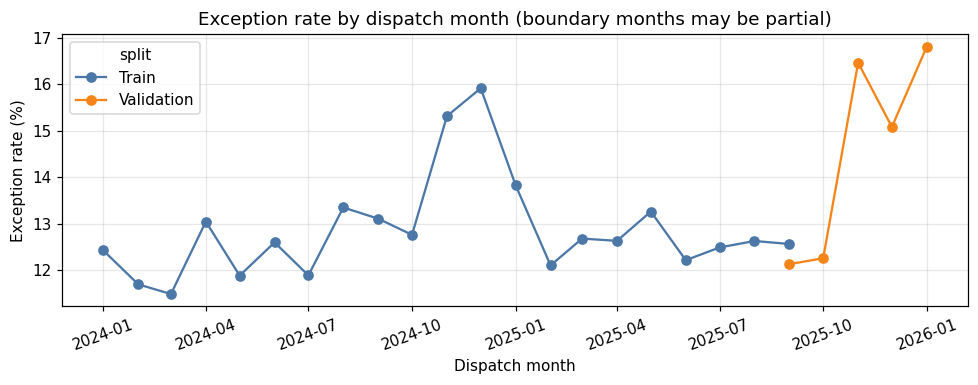

In [4]:
daily = eligible.groupBy(DATE).count().orderBy(DATE).toPandas()
share = daily["count"].cumsum() / eligible_count
validation_start, test_start = [daily.loc[share >= p, DATE].iloc[0] for p in (0.70, 0.85)]
gap = timedelta(days=7)
day = F.col(DATE)
orders = eligible.withColumn(
    "split",
    F.when(day < validation_start - gap, "Train")
    .when(day < validation_start, "Gap")
    .when(day < test_start - gap, "Validation")
    .when(day < test_start, "Gap")
    .otherwise("Test"),
).cache()

splits = orders.groupBy("split").agg(
    F.count("*").alias("orders"), F.min(DATE).alias("first dispatch"),
    F.max(DATE).alias("last dispatch"), F.countDistinct("customer_id").alias("customers"),
).toPandas().set_index("split").reindex(["Train", "Validation", "Test", "Gap"])
splits["share (%)"] = (100 * splits["orders"] / eligible_count).round(2)
display(save(splits, "split_summary"))

# integrity: an order can sit in only one split, and the splits are strictly ordered in time
chk = orders.groupBy("order_id").agg(F.count("*").alias("rows"), F.countDistinct("split").alias("n_splits"))
assert chk.where("rows > 1 OR n_splits > 1").count() == 0, "an order_id appears more than once or in two splits"
assert splits.loc["Train", "last dispatch"] < splits.loc["Validation", "first dispatch"] <= splits.loc["Validation", "last dispatch"] \
       < splits.loc["Test", "first dispatch"], "splits overlap in time"
print("Integrity check passed: every order_id appears once, in exactly one split; splits are in strict date order.")

training_orders = orders.where("split = 'Train'")
development = orders.where("split IN ('Train', 'Validation')")

# class balance of the development splits (test prevalence is reported in the final evaluation)
balance = development.groupBy("split").agg(F.count("*").alias("orders"), F.sum("label").alias("exceptions")).toPandas()
balance = balance.set_index("split").reindex(["Train", "Validation"])
balance["no exception"] = balance["orders"] - balance["exceptions"]
balance["exception rate (%)"] = (100 * balance["exceptions"] / balance["orders"]).round(2)
display(save(balance, "class_balance_dev"))

# customer structure: how many validation/test orders come from customers already seen in training?
seen = training_orders.select("customer_id").distinct().withColumn("seen", F.lit(1))
overlap = (orders.where("split IN ('Validation', 'Test')").join(seen, "customer_id", "left")
           .groupBy("split").agg(F.count("*").alias("orders"), F.count("seen").alias("orders from training customers"),
                                 F.countDistinct("customer_id").alias("customers"),
                                 F.countDistinct(F.when(F.col("seen").isNotNull(), F.col("customer_id"))).alias("customers also in training"))
           .toPandas().set_index("split").reindex(["Validation", "Test"]))
overlap["share of orders (%)"] = (100 * overlap["orders from training customers"] / overlap["orders"]).round(1)
display(save(overlap, "customer_overlap"))
per_cust = training_orders.groupBy("customer_id").count().agg(F.avg("count"), F.percentile_approx("count", 0.5),
                                                              F.max("count")).first()
print(f"Training customers place {per_cust[0]:.2f} orders on average (median {per_cust[1]}, max {per_cust[2]}).")
RUN["customer_overlap_pct"] = overlap["share of orders (%)"].to_dict()

monthly = development.groupBy(F.trunc(DATE, "month").alias("month"), "split").agg(
    (100 * F.avg("label")).alias("exception_rate"), F.count("*").alias("n")
).orderBy("month").toPandas()
ax = monthly.pivot(index="month", columns="split", values="exception_rate").plot(
    marker="o", figsize=(9, 3.6), color={"Train": "#4C78A8", "Validation": "#F58518"},
    title="Exception rate by dispatch month (boundary months may be partial)",
    xlabel="Dispatch month", ylabel="Exception rate (%)", rot=20,
)
ax.grid(alpha=.3)
ax.figure.tight_layout()
ax.figure.savefig(OUT / "fig_prevalence_by_month.png")
plt.show()

## 3. How do I prepare the model inputs?

- **Cell 9 defines the rules.** Use only information available when the order ships. Leave out IDs and later outcomes, combine spellings like `Ontario` and `ON`, and mark invalid numbers as missing. Add **weekday** (weekly workload patterns) and **distance per promised day** (how tight the delivery promise is).
- **Cell 10 applies the rules and shows what they caught.** It counts missing, invalid and spike values in the training data. For example, 999 kg and 1,250 kg show up 224 times, while the largest other weight is 35.38 kg, so they are data-entry codes, not real parcels.

All cleaning rules are fixed rules, so using them on validation and test cannot leak anything. Things that are *learned* (medians, category codes) are fitted on training data only, inside the pipeline in Cell 16.

In [5]:
NUMERIC = [
    "order_value_cad", "parcel_weight_kg", "item_count", "shipping_distance_km",
    "customer_tenure_months", "prior_order_count", "prior_exception_count",
    "address_quality_score", "warehouse_backlog_at_dispatch",
    "pre_dispatch_prep_hours", "promised_delivery_days",
]
CATEGORICAL = [
    "warehouse_id", "destination_province", "destination_zone", "carrier",
    "shipping_service", "order_channel", "device_type", "product_category",
    "inventory_status_at_dispatch", "fragile_item", "weather_forecast_at_dispatch",
]
IDENTIFIERS = ["order_id", "customer_id", "merchant_id"]
POST_DISPATCH = ["actual_delivery_days", "final_delivery_status", "delivery_attempts_total",
                 "refund_issued_after_dispatch", "post_delivery_support_tickets"]   # known only AFTER dispatch -> leakage
REDUNDANT = ["weekend_dispatch"]                                                    # derivable from dispatch_date
assert not set(IDENTIFIERS + POST_DISPATCH + REDUNDANT + [TARGET]) & set(NUMERIC + CATEGORICAL), "leaky or excluded column in the inputs"
assert set(IDENTIFIERS + POST_DISPATCH + REDUNDANT + NUMERIC + CATEGORICAL + [DATE, TARGET]) == set(raw.columns), "a column is unaccounted for"

SPIKES = {
    "order_value_cad": [999999], "parcel_weight_kg": [999, 1250],
    "shipping_distance_km": [12000], "pre_dispatch_prep_hours": [999],
    "promised_delivery_days": [40],
}
ALIASES = {
    "destination_province": {"ontario": "on", "quebec": "qc", "b.c.": "bc"},
    "shipping_service": {"std": "standard", "expres": "express", "same day": "sameday"},
}
KNOWN_VALUES = {
    "destination_province": "ab bc mb nb nl ns nt nu on pe qc sk yt".split(),
    "shipping_service": "standard economy express sameday".split(),
}
MISSING = "__missing_or_unknown__"

def parse_number(name):
    text = F.trim(name)
    grouped = text.rlike(r"^[+-]?\d{1,3}(,\d{3})+(\.\d+)?$")
    number = F.when(grouped, F.regexp_replace(text, ",", "")).otherwise(text).try_cast("double")
    return F.when(F.abs(number) <= np.finfo(float).max, number)

def invalid_number(name):
    number = F.col(name)
    if name == "address_quality_score":
        return ~number.between(0, 100)
    if name in {"parcel_weight_kg", "item_count", "promised_delivery_days"}:
        invalid = number <= 0
    else:
        invalid = number < 0
    return invalid | number.isin(SPIKES[name]) if name in SPIKES else invalid

def clean_category(name):
    value = F.lower(F.trim(name))
    if name in ALIASES:
        mapping = F.create_map(*[F.lit(item) for pair in ALIASES[name].items() for item in pair])
        value = F.coalesce(F.element_at(mapping, value), value)
        value = F.when(value.isin(KNOWN_VALUES[name]), value)
    return F.coalesce(F.when(value != "", value), F.lit(MISSING))

def parse_orders(frame):
    return frame.withColumns({c: parse_number(c) for c in NUMERIC})

def clean_orders(frame):
    cleaned = frame.select(
        "order_id", DATE, "label",
        *[F.when(~invalid_number(c), F.col(c)).alias(c) for c in NUMERIC],
        *[clean_category(c).alias(c) for c in CATEGORICAL],
    )
    return cleaned.withColumns({
        "prior_exception_count": F.when(
            F.col("prior_order_count").isNull() | (F.col("prior_exception_count") <= F.col("prior_order_count")),
            F.col("prior_exception_count"),
        ),
        "dispatch_weekday": F.date_format(DATE, "E"),
        "distance_per_promised_day": F.try_divide("shipping_distance_km", "promised_delivery_days"),
    })

In [6]:
parsed_train = parse_orders(training_orders).cache()
train = clean_orders(parsed_train).cache()
validation = clean_orders(parse_orders(orders.where("split = 'Validation'")))

numeric_checks = []
for c in NUMERIC:
    numeric_checks.extend([
        F.count_if(F.col(c).isNull()).alias(f"{c}_missing"),
        F.count_if(invalid_number(c)).alias(f"{c}_invalid"),
    ])
    if c in SPIKES:
        spike = F.col(c).isin(SPIKES[c])
        numeric_checks.extend([
            F.count_if(spike).alias(f"{c}_spikes"),
            F.max(F.when(~spike, F.col(c))).alias(f"{c}_other_max"),
        ])

audit = parsed_train.agg(
    *numeric_checks,
    F.count_if(F.col("prior_exception_count") > F.col("prior_order_count")).alias("history"),
    F.count_if(F.col("weekend_dispatch").try_cast("int") != F.dayofweek(DATE).isin(1, 7).cast("int")).alias("weekend"),
    *[F.count_if(clean_category(c) == MISSING).alias(f"{c}_unknown") for c in CATEGORICAL],
    *[F.count_if((clean_category(c) != MISSING) & (clean_category(c) != F.lower(c))).alias(f"{c}_repaired")
      for c in ALIASES],
).first().asDict()

numeric_audit = pd.DataFrame({
    "Missing or unparsable": [audit[f"{c}_missing"] for c in NUMERIC],
    "Invalid or spike": [audit[f"{c}_invalid"] for c in NUMERIC],
    "Spike values": [SPIKES.get(c, []) for c in NUMERIC],
    "Rows at spikes": [audit.get(f"{c}_spikes", 0) for c in NUMERIC],
    "Largest other value": [audit.get(f"{c}_other_max") for c in NUMERIC],
}, index=NUMERIC)
display(save(numeric_audit, "numeric_audit"))

numeric = NUMERIC + ["distance_per_promised_day"]
categories = CATEGORICAL + ["dispatch_weekday"]
ranges = pd.DataFrame(
    train.approxQuantile(numeric, [0.01, 0.5, 0.99], 0.001),
    index=numeric, columns=["p01", "median", "p99"],
).round(2)
display(save(ranges, "numeric_ranges_train"))
print("Category repairs:", {c: audit[f"{c}_repaired"] for c in ALIASES})

# which numeric columns ever need a missing-value flag (used only in the section-5 sensitivity check)
MISS_FLAG_COLS = [c for c in NUMERIC if audit[f"{c}_missing"] + audit[f"{c}_invalid"] > 0]
def add_missing_flags(frame):
    return frame.withColumns({f"{c}_was_missing": F.col(c).isNull().cast("double") for c in MISS_FLAG_COLS})

# ---- data-quality log entries for the training-set audit
miss_cols = {c: audit[f"{c}_missing"] for c in NUMERIC if audit[f"{c}_missing"]}
bad_cols = {c: audit[f"{c}_invalid"] for c in NUMERIC if audit[f"{c}_invalid"]}
spike_txt = "; ".join(f"{c}: {SPIKES[c]} x{audit[f'{c}_spikes']} (largest other value {audit[f'{c}_other_max']:.4g})" for c in SPIKES)
log_issue("Missing or unreadable numbers",
          f"Blank or unparsable cells per column: {miss_cols}",
          "Mark as missing; fill with the TRAINING median inside the fitted pipeline.",
          "The median is robust to the extreme values below, and learning it from training data only avoids leakage.",
          "Imputation shrinks variation; missing-ness itself might carry signal (tested with flags in section 5).",
          "Training split", int(sum(miss_cols.values())))
log_issue("Impossible values and sentinel spikes",
          f"Invalid per column: {bad_cols}. Spikes: {spike_txt}. Address scores outside 0-100 are invalid.",
          "Mark as missing (then impute as above).",
          "Sentinels such as 999 kg sit far outside the realistic range, so they are data-entry codes, not genuine parcels.",
          "A genuine extreme order could be lost; the flagged share per column is small.",
          "Training split", int(sum(bad_cols.values())))
log_issue("Inconsistent category spellings and unknown labels",
          f"Province repairs: {audit['destination_province_repaired']}; shipping-service repairs: {audit['shipping_service_repaired']}; "
          f"labels outside the known list (for example 'UNKNOWN') are treated as unknown.",
          "Lower-case, trim, map aliases (Ontario/ON, Std/Standard ...) to one value.",
          "Spelling variants would otherwise split one real category into several sparse ones.",
          "Cleaner categories; a few distinct raw labels are merged.",
          "Training split", int(audit["destination_province_repaired"] + audit["shipping_service_repaired"]))
log_issue("Blank or unknown categories",
          "Blanks per column: " + str({c: audit[f"{c}_unknown"] for c in CATEGORICAL if audit[f"{c}_unknown"]}) +
          ". The weather field also has an explicit 'Unknown' label from the source system.",
          "Keep as an explicit 'missing or unknown' category.",
          "Keeps the order in the data; the model can learn that unknown fields behave differently.",
          "If blanks are random this adds a little noise.", "Training split", int(sum(audit[f"{c}_unknown"] for c in CATEGORICAL)))
log_issue("Inconsistent history and weekend flag",
          f"prior_exception_count > prior_order_count: {audit['history']} rows; weekend_dispatch disagrees with the date: {audit['weekend']} rows.",
          "No repair needed (rule kept in code in case of future files); weekday is derived from the date and the redundant flag is not used.",
          "A checked rule that found nothing is evidence the fields are consistent.", "None observed.",
          "Training split", int(audit["history"] + audit["weekend"]))

,Missing or unparsable,Invalid or spike,Spike values,Rows at spikes,Largest other value
order_value_cad,1381,257,[999999],111,2634.61
parcel_weight_kg,3255,547,"[999, 1250]",224,35.38
item_count,0,0,[],0,NaN
shipping_distance_km,2225,408,[12000],212,2720.80
customer_tenure_months,2192,0,[],0,NaN
prior_order_count,0,0,[],0,NaN
prior_exception_count,0,0,[],0,NaN
address_quality_score,6394,574,[],0,NaN
warehouse_backlog_at_dispatch,0,0,[],0,NaN
pre_dispatch_prep_hours,0,565,[999],275,102.30


,p01,median,p99
order_value_cad,9.55,73.87,543.66
parcel_weight_kg,0.16,1.16,8.07
item_count,1.00,3.00,7.00
shipping_distance_km,39.50,363.60,1325.20
customer_tenure_months,3.00,23.00,81.00
prior_order_count,0.00,11.00,41.00
prior_exception_count,0.00,1.00,8.00
address_quality_score,42.60,76.90,100.00
warehouse_backlog_at_dispatch,7.00,16.00,50.00
pre_dispatch_prep_hours,1.00,11.70,45.80


Category repairs: {'destination_province': 516, 'shipping_service': 749}


### Which columns did I leave out, and why?

**Cell 12 shows the evidence.** A column is **leakage** if it is only known after dispatch. These look very predictive, but they would not exist when the model has to decide.

- **Five post-dispatch columns are excluded.** `post_delivery_support_tickets` (AUC 0.90), `actual_delivery_days` (0.87), `delivery_attempts_total` (0.77), `refund_issued_after_dispatch` (0.73) and `final_delivery_status`, which is almost a copy of the label (“Delivered” orders have a 0.3% exception rate, every other status is above 99%).
- **Identifiers are excluded.** `order_id`, `customer_id` and `merchant_id` identify rows; they let a model memorise instead of generalise.
- **`weekend_dispatch` is excluded.** It is just the dispatch date again, replaced by `dispatch_weekday`.
- **One honest assumption:** `prior_order_count` and `prior_exception_count` are kept. I assume they are snapshots from *before* this order. The file has no timestamp to prove it, but they are only weakly predictive (AUC 0.53 and 0.56), so a small leak could not explain the results.

In [7]:
POST_NUMERIC = ["actual_delivery_days", "delivery_attempts_total", "refund_issued_after_dispatch", "post_delivery_support_tickets"]
lk = training_orders.select("label", "final_delivery_status",
                            *[parse_number(c).alias(c) for c in POST_NUMERIC + ["prior_order_count", "prior_exception_count"]]).toPandas()
def single_auc(col):
    m = lk[col].notna()
    return roc_auc_score(lk.loc[m, "label"], lk.loc[m, col])
status_rate = lk.groupby("final_delivery_status", dropna=False)["label"].agg(["mean", "size"])
status_txt = "; ".join(f"{k}: {v['mean']:.1%} (n={int(v['size'])})" for k, v in status_rate.iterrows())
id_counts = training_orders.agg(F.count("*").alias("rows"), F.countDistinct("order_id").alias("order_id"),
                                F.countDistinct("customer_id").alias("customer_id"),
                                F.countDistinct("merchant_id").alias("merchant_id")).first().asDict()

leak = pd.DataFrame([
    ("actual_delivery_days", "Excluded (leakage)", "Known only once delivery finishes.", f"single-column ROC-AUC {single_auc('actual_delivery_days'):.2f}"),
    ("final_delivery_status", "Excluded (leakage)", "The outcome itself in another form.", "exception rate by status: " + status_txt),
    ("delivery_attempts_total", "Excluded (leakage)", "Counted while the parcel is being delivered.", f"single-column ROC-AUC {single_auc('delivery_attempts_total'):.2f}"),
    ("refund_issued_after_dispatch", "Excluded (leakage)", "The name says it happens after dispatch.", f"single-column ROC-AUC {single_auc('refund_issued_after_dispatch'):.2f}"),
    ("post_delivery_support_tickets", "Excluded (leakage)", "Created after delivery.", f"single-column ROC-AUC {single_auc('post_delivery_support_tickets'):.2f}"),
    ("order_id, customer_id, merchant_id", "Excluded (identifiers)", "Keys identify rows; they do not generalise to new orders and let a model memorise.",
     f"{id_counts['customer_id']:,} customers and {id_counts['merchant_id']:,} merchants over {id_counts['rows']:,} training orders"),
    ("weekend_dispatch", "Excluded (redundant)", "Fully determined by dispatch_date; replaced by dispatch_weekday.", f"disagreed with the date in {audit['weekend']} rows"),
    ("prior_order_count, prior_exception_count", "KEPT (assumption)", "Customer history before this order. It must be a snapshot taken before dispatch and must not include this order; the file has no timestamp to prove it.",
     f"ROC-AUC {single_auc('prior_order_count'):.2f} / {single_auc('prior_exception_count'):.2f}: weakly predictive, so a small leak could not explain the results"),
], columns=["Column(s)", "Decision", "Reason", "Evidence (training split)"]).set_index("Column(s)")
pd.set_option("display.max_colwidth", 200)
display(save(leak, "leakage_review"))

log_issue("Post-dispatch columns (target leakage)",
          "; ".join(f"{c}: AUC {single_auc(c):.2f}" for c in POST_NUMERIC) + "; final_delivery_status is almost a copy of the label.",
          "Exclude all five from the model inputs (asserted in code).",
          "They are only known after dispatch, so they cannot be used at prediction time even though they are highly predictive.",
          "Prevents an unrealistically high score. Reported accuracy is lower but honest.", "Whole file", len(POST_DISPATCH))
log_issue("Identifiers and redundant fields",
          f"customer_id has {id_counts['customer_id']:,} distinct values in {id_counts['rows']:,} training rows; weekend_dispatch duplicates the date.",
          "Exclude order_id, customer_id, merchant_id and weekend_dispatch.",
          "Identifiers memorise rather than generalise.", "None expected.", "Whole file", 4)
log_issue("Customers repeat across time",
          overlap["share of orders (%)"].to_dict().__repr__() + " percent of validation/test orders come from customers present in training.",
          "Keep them; report the overlap.",
          "This mirrors production, where returning customers are scored too.",
          "Results describe a population that includes returning customers; brand-new customers may behave differently.",
          "Validation and test", int(overlap["orders from training customers"].sum()))

,Decision,Reason,Evidence (training split)
Column(s),,,
actual_delivery_days,Excluded (leakage),Known only once delivery finishes.,single-column ROC-AUC 0.87
final_delivery_status,Excluded (leakage),The outcome itself in another form.,exception rate by status: Delayed: 99.8% (n=2950); Delivered: 0.3% (n=71820); Exception: 99.7% (n=4938); Lost: 99.6% (n=547); Returned: 99.6% (n=1959)
delivery_attempts_total,Excluded (leakage),Counted while the parcel is being delivered.,single-column ROC-AUC 0.77
refund_issued_after_dispatch,Excluded (leakage),The name says it happens after dispatch.,single-column ROC-AUC 0.73
post_delivery_support_tickets,Excluded (leakage),Created after delivery.,single-column ROC-AUC 0.90
"order_id, customer_id, merchant_id",Excluded (identifiers),Keys identify rows; they do not generalise to new orders and let a model memorise.,"37,683 customers and 820 merchants over 82,214 training orders"
weekend_dispatch,Excluded (redundant),Fully determined by dispatch_date; replaced by dispatch_weekday.,disagreed with the date in 0 rows
"prior_order_count, prior_exception_count",KEPT (assumption),Customer history before this order. It must be a snapshot taken before dispatch and must not include this order; the file has no timestamp to prove it.,"ROC-AUC 0.53 / 0.56: weakly predictive, so a small leak could not explain the results"


### What do the inputs look like?

**Cell 14 draws two figures from the cleaned training data.**

1. **Numeric inputs by outcome.** Orders with an exception tend to travel **longer distances** and have **lower address-quality scores**. Order value, weight and prep hours barely differ.
2. **Exception rate by category** (dashed line = overall 12.9%). It is highest for **storm** weather (about 21%), **rural** zones, **economy** service and **back-order cleared** stock, and lowest for **express**. Dispatch weekday is almost flat.

In plain terms: the signal is real but modest, and it comes from route, service and weather rather than from the order itself.

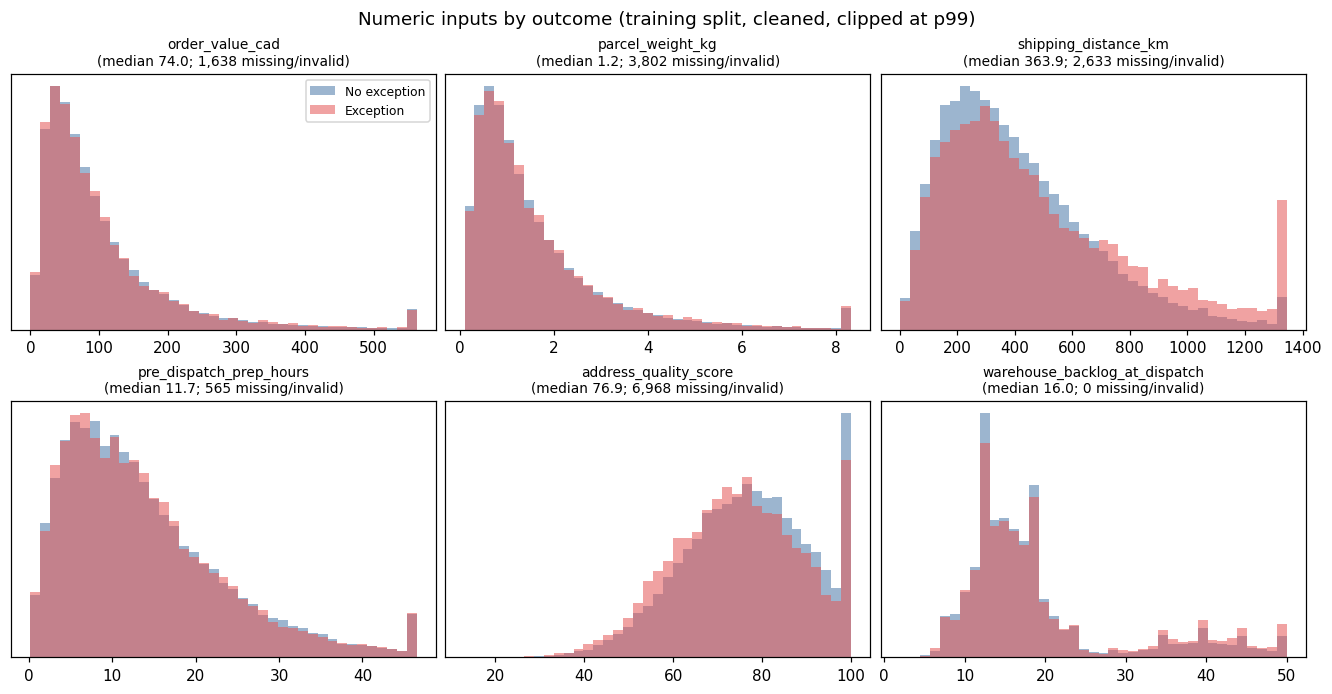

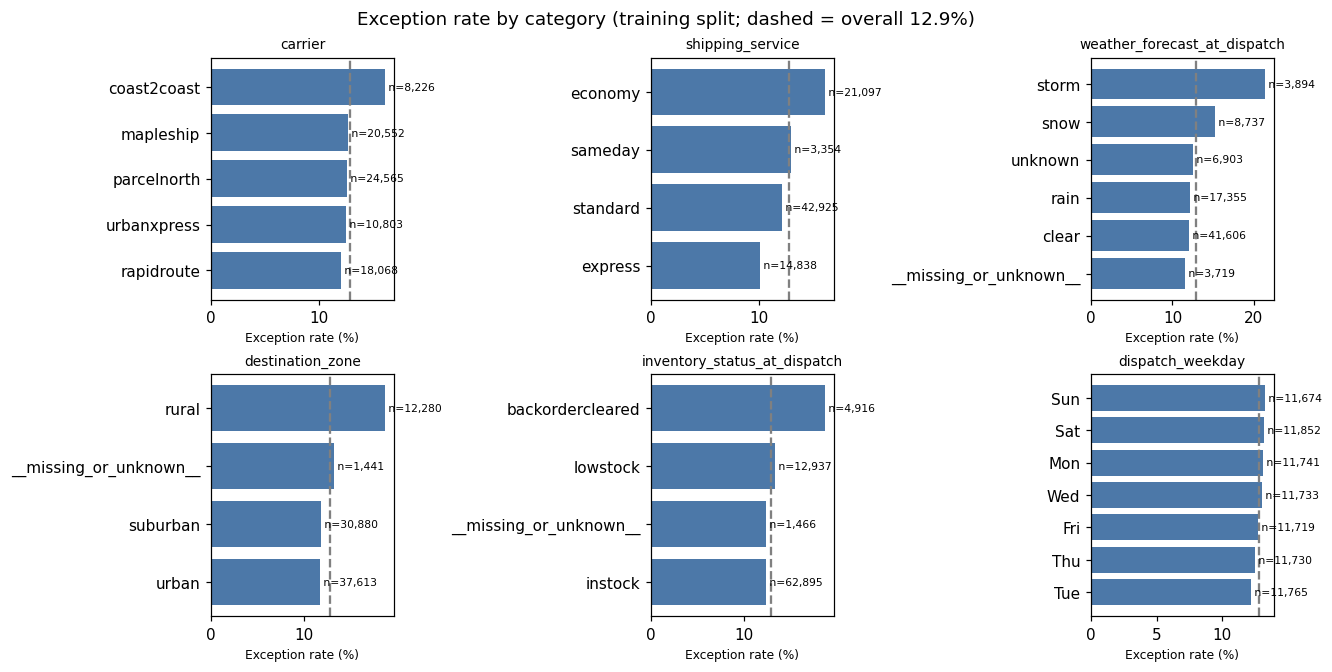

In [8]:
FIG_NUM = ["order_value_cad", "parcel_weight_kg", "shipping_distance_km", "pre_dispatch_prep_hours",
           "address_quality_score", "warehouse_backlog_at_dispatch"]
FIG_CAT = ["carrier", "shipping_service", "weather_forecast_at_dispatch", "destination_zone",
           "inventory_status_at_dispatch", "dispatch_weekday"]
train_pd = train.select("label", *FIG_NUM, *FIG_CAT).toPandas()
train_rate = train_pd["label"].mean()

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), layout="constrained")
for ax, c in zip(axes.ravel(), FIG_NUM):
    x = train_pd[[c, "label"]].dropna()
    hi = x[c].quantile(0.99)
    bins = np.linspace(x[c].min(), hi, 40)
    for lab, color, name in [(0, "#4C78A8", "No exception"), (1, "#E45756", "Exception")]:
        ax.hist(x.loc[x["label"] == lab, c].clip(upper=hi), bins=bins, density=True, alpha=.55, color=color, label=name)
    ax.set_title(f"{c}\n(median {x[c].median():.1f}; {train_pd[c].isna().sum():,} missing/invalid)", fontsize=9)
    ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle("Numeric inputs by outcome (training split, cleaned, clipped at p99)")
fig.savefig(OUT / "fig_numeric_distributions.png")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for ax, c in zip(axes.ravel(), FIG_CAT):
    g = train_pd.groupby(c)["label"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(g.index.astype(str), 100 * g["mean"], color="#4C78A8")
    ax.axvline(100 * train_rate, color="gray", linestyle="--")
    ax.set_title(c, fontsize=9); ax.set_xlabel("Exception rate (%)", fontsize=8)
    for i, (rate, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(100 * rate, i, f" n={n:,}", va="center", fontsize=7)
fig.suptitle(f"Exception rate by category (training split; dashed = overall {train_rate:.1%})")
fig.savefig(OUT / "fig_category_rates.png")
plt.show()

## 4. What am I comparing?

**Cell 16 asks whether a random forest can rank risky orders better than logistic regression, our simpler baseline.**

**Logistic regression** is an interpretable baseline when inputs add up to a risk. **Random forest** can capture combinations, like weather and route together.

1. **Prepare the inputs (training data only).** Missing numbers are filled with the *training* median, and categories like carrier become yes/no columns using codes learned from *training* orders. The same fitted pipeline is then applied to validation and test.
2. **Tune both models on validation.** Search space: **36 forests** (`maxDepth` 4/8/12 × `minInstancesPerNode` 1/25/100 × `featureSubsetStrategy` sqrt/one-third × `numTrees` 50/100) and **10 logistic regressions** (`regParam` × `elasticNetParam`).
3. **Pick by validation PR-AUC.** Exceptions are the minority class and no cutoff exists yet, so I need a score for ranking the minority class across all cutoffs. I use **average precision**. (I avoided the trapezoid version: it gives a do-nothing model about 0.57. Two all-zero logistic models in the table score 0.149, the exception rate, which confirms the metric is behaving.)

**Winners.** Forest: depth 12, min 25 per node, one-third of features, 100 trees (**validation PR-AUC 0.265**). Baseline: L1 logistic regression with regParam 0.001 (**0.256**).

- **Regularisation mattered.** Depth 12 with min 1 per node memorises the training data (train PR-AUC 0.63 vs validation 0.26). Min 25 keeps most of the benefit with a much smaller gap (0.33 vs 0.27).
- **The top forests are practically tied** (the best five are within 0.003), so the exact winner is partly noise. Depth 12 and 100 trees sit at the edge of the grid.

In [9]:
filled_note = "median-imputed"

def build_preprocess(num, cat):
    return Pipeline(stages=[
        Imputer(strategy="median", inputCols=num, outputCols=[f"{c}_filled" for c in num], relativeError=0.001),
        StringIndexer(inputCols=cat, outputCols=[f"{c}_index" for c in cat], handleInvalid="keep"),
        OneHotEncoder(inputCols=[f"{c}_index" for c in cat], outputCols=[f"{c}_encoded" for c in cat], dropLast=False),
        VectorAssembler(inputCols=[f"{c}_filled" for c in num] + [f"{c}_encoded" for c in cat], outputCol="features"),
    ])

def to_matrix(frame, fitted):
    # fixed partitioning and row order -> the random forest is repeatable on any machine
    return (fitted.transform(frame).select("order_id", "label", "features")
            .repartitionByRange(8, "order_id").sortWithinPartitions("order_id"))

def score(model, matrix):
    return model.transform(matrix).select(
        "order_id", "label", vector_to_array("probability")[1].alias("score")
    ).toPandas()

def pr_auc(y, s):
    # PR-AUC = average precision (step-wise area). The trapezoid rule is NOT used: it gives a constant, no-skill
    # score a PR-AUC of about 0.57 instead of the exception rate, which would make a do-nothing model look good.
    return average_precision_score(y, s)

def rank_metrics(scored):
    y, s = scored["label"].to_numpy(), scored["score"].to_numpy()
    return pr_auc(y, s), roc_auc_score(y, s)

def sweep(scored):
    # every possible cutoff ("alert if score >= threshold") with its confusion counts; first row = alert nobody
    y = scored["label"].to_numpy().astype(int); s = scored["score"].to_numpy()
    order = np.argsort(-s, kind="stable"); s, y = s[order], y[order]
    last = np.r_[s[1:] != s[:-1], True]
    tp = np.cumsum(y)[last]; alerts = (np.arange(len(y)) + 1)[last]; thr = s[last]
    P = int(y.sum())
    out = pd.DataFrame({"threshold": np.r_[np.inf, thr], "alerts": np.r_[0, alerts], "TP": np.r_[0, tp]})
    out["FP"] = out["alerts"] - out["TP"]; out["FN"] = P - out["TP"]
    out["precision"] = (out["TP"] / out["alerts"].replace(0, np.nan)).fillna(0.0)
    out["recall"] = out["TP"] / P
    out["F1"] = 2 * out["TP"] / (out["alerts"] + P)
    out["cost"] = COST_FP * out["FP"] + COST_FN * out["FN"]
    return out

train_f, val_f = add_missing_flags(train), add_missing_flags(validation)
preprocess = build_preprocess(numeric, categories).fit(train)          # <- fitted on TRAINING orders only
train_matrix = to_matrix(train, preprocess).cache()
val_matrix = to_matrix(validation, preprocess).cache()
print(f"{train_matrix.count():,} training rows, {val_matrix.count():,} validation rows, "
      f"{len(train_matrix.first()['features']):,} model inputs after encoding")

if QUICK:
    RF_GRID = {"maxDepth": [4, 8], "minInstancesPerNode": [1, 50], "featureSubsetStrategy": ["sqrt"], "numTrees": [20]}
    LR_GRID = {"regParam": [0.0, 0.01], "elasticNetParam": [0.0]}
else:
    RF_GRID = {"maxDepth": [4, 8, 12], "minInstancesPerNode": [1, 25, 100],
               "featureSubsetStrategy": ["sqrt", "onethird"], "numTrees": [50, 100]}
    LR_GRID = {"regParam": [0.0, 0.001, 0.01, 0.1], "elasticNetParam": [0.0, 0.5, 1.0]}
rf_candidates = [dict(zip(RF_GRID, v)) for v in product(*RF_GRID.values())]
lr_candidates = [{"regParam": r, "elasticNetParam": e} for r in LR_GRID["regParam"] for e in LR_GRID["elasticNetParam"]
                 if not (r == 0 and e != 0)]          # with no penalty the elastic-net mix is irrelevant
print(f"Search space: {len(rf_candidates)} forests {RF_GRID}")
print(f"              {len(lr_candidates)} logistic regressions {LR_GRID}")
RUN["search_space"] = {"random_forest": RF_GRID, "logistic_regression": LR_GRID}

results, best = [], {}
def run_candidate(family, params, estimator):
    t = time.time(); model = estimator.fit(train_matrix); secs = time.time() - t
    v, tr = score(model, val_matrix), score(model, train_matrix)
    vp, vroc = rank_metrics(v); tp_, troc = rank_metrics(tr)
    results.append({"Family": family, **params, "Val PR-AUC": vp, "Val ROC-AUC": vroc,
                    "Train PR-AUC": tp_, "Train ROC-AUC": troc, "Fit seconds": secs})
    if family not in best or vp > best[family]["pr"]:
        best[family] = {"pr": vp, "params": params, "model": model, "val": v}
    with open(OUT / "progress.log", "a") as fh:
        fh.write(f"{time.strftime('%H:%M:%S')} {family} {params} fit {secs:.0f}s val PR-AUC {vp:.4f}\n")

for p in lr_candidates:
    run_candidate("Logistic regression", p, LogisticRegression(maxIter=100, **p))
for p in rf_candidates:
    run_candidate("Random forest", p, RandomForestClassifier(seed=SEED, **p))

tuning = pd.DataFrame(results)
tuning["Train-Val PR-AUC gap"] = tuning["Train PR-AUC"] - tuning["Val PR-AUC"]
tuning = tuning.sort_values(["Family", "Val PR-AUC"], ascending=[True, False], kind="stable").reset_index(drop=True)
save(tuning, "tuning_results")
LRF, RFF = "Logistic regression", "Random forest"
for fam in (LRF, RFF):
    cols = [c for c in tuning.columns if c not in ("Family",) and not (fam == LRF and c in RF_GRID) and not (fam == RFF and c in LR_GRID)]
    print(f"\n{fam}: all {int((tuning['Family'] == fam).sum())} candidates, ranked by validation PR-AUC")
    display(tuning[tuning["Family"] == fam][cols].round(4).reset_index(drop=True))

BASE, FOREST = "Logistic regression (baseline)", "Random forest (chosen)"
final_models = {BASE: best[LRF]["model"], FOREST: best[RFF]["model"]}
val_scores = {BASE: best[LRF]["val"], FOREST: best[RFF]["val"]}
chosen_params = {BASE: best[LRF]["params"], FOREST: best[RFF]["params"]}
print("\nWinning settings (selected on validation PR-AUC):")
for k, v in chosen_params.items():
    print(f"  {k}: {v}")
RUN["chosen_params"] = chosen_params
RUN["n_candidates"] = {"random_forest": len(rf_candidates), "logistic_regression": len(lr_candidates)}

82,214 training rows, 16,868 validation rows, 87 model inputs after encoding
Search space: 36 forests {'maxDepth': [4, 8, 12], 'minInstancesPerNode': [1, 25, 100], 'featureSubsetStrategy': ['sqrt', 'onethird'], 'numTrees': [50, 100]}
              10 logistic regressions {'regParam': [0.0, 0.001, 0.01, 0.1], 'elasticNetParam': [0.0, 0.5, 1.0]}



Logistic regression: all 10 candidates, ranked by validation PR-AUC


,regParam,elasticNetParam,Val PR-AUC,Val ROC-AUC,Train PR-AUC,Train ROC-AUC,Fit seconds,Train-Val PR-AUC gap
0,0.001,1.0,0.2562,0.6484,0.2254,0.6435,3.5449,-0.0307
1,0.001,0.5,0.2557,0.6476,0.2259,0.6440,5.9834,-0.0298
2,0.000,0.0,0.2553,0.6469,0.2260,0.6444,5.1925,-0.0292
3,0.001,0.0,0.2552,0.6468,0.2260,0.6444,3.1405,-0.0292
4,0.010,0.0,0.2552,0.6465,0.2259,0.6444,2.2121,-0.0293
5,0.010,0.5,0.2549,0.6474,0.2237,0.6406,2.5778,-0.0311
6,0.100,0.0,0.2541,0.6448,0.2245,0.6430,1.8427,-0.0296
7,0.010,1.0,0.2487,0.6385,0.2183,0.6321,2.4540,-0.0304
8,0.100,0.5,0.1490,0.5000,0.1286,0.5000,0.7159,-0.0204
9,0.100,1.0,0.1490,0.5000,0.1286,0.5000,0.4983,-0.0204



Random forest: all 36 candidates, ranked by validation PR-AUC


,Val PR-AUC,Val ROC-AUC,Train PR-AUC,Train ROC-AUC,Fit seconds,maxDepth,minInstancesPerNode,featureSubsetStrategy,numTrees,Train-Val PR-AUC gap
0,0.2654,0.6509,0.3285,0.6936,86.4209,12.0,25.0,onethird,100.0,0.0630
1,0.2651,0.6490,0.3204,0.6733,10.6776,8.0,1.0,onethird,50.0,0.0553
2,0.2645,0.6499,0.3170,0.6866,19.0744,8.0,1.0,sqrt,100.0,0.0525
3,0.2642,0.6503,0.2943,0.6813,62.8493,12.0,25.0,sqrt,100.0,0.0301
4,0.2629,0.6482,0.3213,0.6751,24.3113,8.0,1.0,onethird,100.0,0.0584
5,0.2629,0.6457,0.2686,0.6559,22.9811,8.0,25.0,onethird,100.0,0.0057
6,0.2629,0.6500,0.2949,0.6788,28.0139,12.0,25.0,sqrt,50.0,0.0321
7,0.2622,0.6473,0.3140,0.6831,9.0777,8.0,1.0,sqrt,50.0,0.0518
8,0.2621,0.6472,0.2557,0.6566,18.5773,8.0,25.0,sqrt,100.0,-0.0063
9,0.2614,0.6491,0.3244,0.6901,33.5023,12.0,25.0,onethird,50.0,0.0630



Winning settings (selected on validation PR-AUC):
  Logistic regression (baseline): {'regParam': 0.001, 'elasticNetParam': 1.0}
  Random forest (chosen): {'maxDepth': 12, 'minInstancesPerNode': 25, 'featureSubsetStrategy': 'onethird', 'numTrees': 100}


### Do the extra ideas help? (checks only, nothing here changes the model)

**Cell 18 refits the models with and without each idea and compares validation PR-AUC.**

- **Engineered features: tiny gains.** For the forest, raw inputs score 0.2638, adding weekday 0.2665, adding distance per promised day 0.2643, both 0.2659. For logistic regression, nothing moves (0.2559 → 0.2562). They are justified by logic and give a small, within-noise gain; distance per promised day is the sixth most important forest input.
- **Missing-value flags: no gain** (0.2640), so not adopted.
- **Class weights (an alternative to resampling): slightly worse** (forest 0.2596 vs 0.2654, logistic 0.2525 vs 0.2562), so not adopted.

The bar for adopting an idea was a gain bigger than the ~0.003 noise between near-tied candidates.

In [10]:
def make_estimator(family, weight=False):
    p = best[family]["params"]
    kw = {"weightCol": "weight"} if weight else {}
    return LogisticRegression(maxIter=100, **p, **kw) if family == LRF else RandomForestClassifier(seed=SEED, **p, **kw)

variants = {
    "Raw inputs only": (NUMERIC, CATEGORICAL),
    "+ distance_per_promised_day": (NUMERIC + ["distance_per_promised_day"], CATEGORICAL),
    "+ dispatch_weekday": (NUMERIC, CATEGORICAL + ["dispatch_weekday"]),
    "+ both (used in the final model)": (numeric, categories),
    "+ both + missing-value flags (not adopted)": (numeric + [f"{c}_was_missing" for c in MISS_FLAG_COLS], categories),
}
abl = []
for vname, (num, cat) in variants.items():
    pre = build_preprocess(num, cat).fit(train_f)
    tm, vm = to_matrix(train_f, pre), to_matrix(val_f, pre)
    row = {"Inputs": vname}
    for fam in (LRF, RFF):
        v = score(make_estimator(fam).fit(tm), vm)
        row[f"{fam} val PR-AUC"], row[f"{fam} val ROC-AUC"] = rank_metrics(v)
    abl.append(row)
ablation = pd.DataFrame(abl).set_index("Inputs")
display(save(ablation.round(4), "feature_ablation"))

# class-weight check
pos_rate = train.agg(F.avg("label")).first()[0]
w_train = train_matrix.withColumn("weight", F.when(F.col("label") == 1, 0.5 / pos_rate).otherwise(0.5 / (1 - pos_rate)))
cw = []
for fam in (LRF, RFF):
    base_row = tuning[(tuning["Family"] == fam)].iloc[0]
    v = score(make_estimator(fam, weight=True).fit(w_train), val_matrix)
    pr, roc = rank_metrics(v)
    cw.append({"Model": fam, "Val PR-AUC unweighted": base_row["Val PR-AUC"], "Val PR-AUC class-weighted": pr,
               "Val ROC-AUC unweighted": base_row["Val ROC-AUC"], "Val ROC-AUC class-weighted": roc,
               "Best val F1 unweighted": sweep(best[fam]["val"])["F1"].max(), "Best val F1 class-weighted": sweep(v)["F1"].max()})
class_weight_check = pd.DataFrame(cw).set_index("Model")
display(save(class_weight_check.round(4), "class_weight_check"))

,Logistic regression val PR-AUC,Logistic regression val ROC-AUC,Random forest val PR-AUC,Random forest val ROC-AUC
Inputs,,,,
Raw inputs only,0.2559,0.6485,0.2638,0.6496
+ distance_per_promised_day,0.2559,0.6484,0.2643,0.6510
+ dispatch_weekday,0.2561,0.6484,0.2665,0.6518
+ both (used in the final model),0.2562,0.6484,0.2659,0.6506
+ both + missing-value flags (not adopted),0.2560,0.6483,0.2640,0.6507


,Val PR-AUC unweighted,Val PR-AUC class-weighted,Val ROC-AUC unweighted,Val ROC-AUC class-weighted,Best val F1 unweighted,Best val F1 class-weighted
Model,,,,,,
Logistic regression,0.2562,0.2525,0.6484,0.6480,0.3222,0.3208
Random forest,0.2654,0.2596,0.6509,0.6492,0.3190,0.3154


## 5. When does a score become an alert?

**Cell 20 turns scores into alerts, using validation data only.** An order is flagged when its score is at or above a cutoff. I compare three rules:

1. **F1-optimal (my main rule).** Best balance of precision and recall when costs are unknown. Forest cutoff **0.1344**: it flags 34% of validation orders, catches 53% of exceptions, and 23% of alerts are real.
2. **Cost-optimal.** Minimises wasted checks + 5 × misses. Forest cutoff **0.1401**.
3. **Capacity (top 20%).** Alert only the 20% highest scores. Forest cutoff **0.1600**.

Three things to say out loud:

- **A model is worth it.** On validation, “alert nobody” costs 745 per 1,000 orders and the forest costs about 617, roughly 17% less. “Alert everybody” costs 851.
- **The cost rule is very sensitive to my assumption.** At 2× the cutoff alerts only 3% of orders, at 5× about 30%, at 10× about 80%. So the cost ratio must come from the business, not from me.
- **Scores are not probabilities.** A forest’s scores are not calibrated, so these are score cutoffs, not “14% chance” statements.

All cutoffs are frozen before the test set is touched. The last table shows the over/underfitting check: the forest’s PR-AUC drops from 0.329 on train to 0.265 on validation.

In [11]:
def pick_f1(sw):
    return sw.sort_values(["F1", "precision", "threshold"], ascending=False).iloc[0]["threshold"]

def pick_cost(sw, ratio=COST_FN / COST_FP):
    c = sw["FP"] + ratio * sw["FN"]
    return sw.assign(_c=c).sort_values(["_c", "threshold"], ascending=[True, False]).iloc[0]["threshold"]

def pick_capacity(scored, frac=CAPACITY):
    s = np.sort(scored["score"].to_numpy())[::-1]
    return float(s[int(np.ceil(frac * len(s))) - 1])

def at_threshold(scored, thr):
    y = scored["label"].to_numpy().astype(int); alert = scored["score"].to_numpy() >= thr
    tp = int((alert & (y == 1)).sum()); fp = int((alert & (y == 0)).sum())
    fn = int((~alert & (y == 1)).sum()); tn = int((~alert & (y == 0)).sum())
    n = len(y)
    return {"Threshold": thr, "Alerts": tp + fp, "Alert rate": (tp + fp) / n, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Precision": tp / max(tp + fp, 1), "Recall": tp / max(tp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1),
            "Accuracy": (tn + tp) / n, "Cost per 1,000 orders": 1000 * (COST_FP * fp + COST_FN * fn) / n}

RULES = ["F1-optimal", "Cost-optimal (FN = 5 x FP)", "Capacity (top 20%)"]
CUTS = {}
for name in (BASE, FOREST):
    sw = sweep(val_scores[name])
    CUTS[name] = {RULES[0]: pick_f1(sw), RULES[1]: pick_cost(sw), RULES[2]: pick_capacity(val_scores[name])}

rows = []
for name in (BASE, FOREST):
    for rule, thr in CUTS[name].items():
        rows.append({"Model": name, "Rule": rule, **at_threshold(val_scores[name], thr)})
vs = val_scores[FOREST]
rows.append({"Model": "Reference", "Rule": "Alert nobody", **at_threshold(vs, np.inf)})
rows.append({"Model": "Reference", "Rule": "Alert everybody", **at_threshold(vs, -np.inf)})
cutoff_table = pd.DataFrame(rows).set_index(["Model", "Rule"])
print("VALIDATION data. Cutoffs chosen here are frozen for the test set.")
display(save(cutoff_table.round(4), "cutoffs_validation"))

# how sensitive is the cost-optimal cutoff to the assumed cost ratio?
sw = sweep(val_scores[FOREST])
sens = []
for ratio in (2, 3, 5, 10, 20):
    thr = pick_cost(sw, ratio); r = at_threshold(val_scores[FOREST], thr)
    sens.append({"FN cost / FP cost": ratio, "Threshold": thr, "Alert rate": r["Alert rate"], "Precision": r["Precision"], "Recall": r["Recall"]})
display(save(pd.DataFrame(sens).set_index("FN cost / FP cost").round(4), "cost_ratio_sensitivity"))

# over/underfitting evidence on the training split for the two chosen models
diag = pd.DataFrame({"Train PR-AUC": [rank_metrics(score(final_models[n], train_matrix))[0] for n in (BASE, FOREST)],
                     "Validation PR-AUC": [rank_metrics(val_scores[n])[0] for n in (BASE, FOREST)]}, index=[BASE, FOREST])
display(diag.round(4))
RUN["cutoffs"] = {m: {r: float(t) for r, t in d.items()} for m, d in CUTS.items()}

VALIDATION data. Cutoffs chosen here are frozen for the test set.


Threshold  Alerts  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                     0.1451    5011   
                               Cost-optimal (FN = 5 x FP)     0.1451    5011   
                               Capacity (top 20%)             0.1678    3374   
Random forest (chosen)         F1-optimal                     0.1344    5787   
                               Cost-optimal (FN = 5 x FP)     0.1401    5124   
                               Capacity (top 20%)             0.1600    3374   
Reference                      Alert nobody                      inf       0   
                               Alert everybody                  -inf   16868   

                                                           Alert rate     TN  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                      0.2971  10556   
                               Cost-optimal (FN = 5 x FP)      0.2971  10556   
                               Capacity (top 20%)              0.2000  11887   
Random forest (chosen)         F1-optimal                      0.3431   9892   
                               Cost-optimal (FN = 5 x FP)      0.3038  10446   
                               Capacity (top 20%)              0.2000  11898   
Reference                      Alert nobody                    0.0000  14355   
                               Alert everybody                 1.0000      0   

                                                              FP    FN    TP  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                   3799  1301  1212   
                               Cost-optimal (FN = 5 x FP)   3799  1301  1212   
                               Capacity (top 20%)           2468  1607   906   
Random forest (chosen)         F1-optimal                   4463  1189  1324   
                               Cost-optimal (FN = 5 x FP)   3909  1298  1215   
                               Capacity (top 20%)           2457  1596   917   
Reference                      Alert nobody                    0  2513     0   
                               Alert everybody             14355     0  2513   

                                                           Precision  Recall  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                     0.2419  0.4823   
                               Cost-optimal (FN = 5 x FP)     0.2419  0.4823   
                               Capacity (top 20%)             0.2685  0.3605   
Random forest (chosen)         F1-optimal                     0.2288  0.5269   
                               Cost-optimal (FN = 5 x FP)     0.2371  0.4835   
                               Capacity (top 20%)             0.2718  0.3649   
Reference                      Alert nobody                   0.0000  0.0000   
                               Alert everybody                0.1490  1.0000   

                                                               F1  Accuracy  \
Model                          Rule                                           
Logistic regression (baseline) F1-optimal                  0.3222    0.6977   
                               Cost-optimal (FN = 5 x FP)  0.3222    0.6977   
                               Capacity (top 20%)          0.3078    0.7584   
Random forest (chosen)         F1-optimal                  0.3190    0.6649   
                               Cost-optimal (FN = 5 x FP)  0.3182    0.6913   
                               Capacity (top 20%)          0.3115    0.7597   
Reference                      Alert nobody                0.0000    0.8510   
                               Alert everybody             0.2593    0.1490   

                                                           Cost 

,Threshold,Alert rate,Precision,Recall
FN cost / FP cost,,,,
2,0.2841,0.0280,0.4492,0.0844
3,0.1872,0.1131,0.3218,0.2443
5,0.1401,0.3038,0.2371,0.4835
10,0.0847,0.7977,0.1682,0.9005
20,0.0760,0.9621,0.1531,0.9889


,Train PR-AUC,Validation PR-AUC
Logistic regression (baseline),0.2254,0.2562
Random forest (chosen),0.3285,0.2654


## 6. What does the final test tell us?

**Cell 22 tests both models once on the newest orders, using the cutoffs already chosen.** Nothing is re-fitted on test data.

**Why look beyond accuracy?** Flagging nothing would be **83.9% accurate** and catch **zero** exceptions.

- **PR-AUC** compares models across cutoffs and focuses on the rare class. The no-skill line is the exception rate, 0.161.
- **Precision, recall, F1** describe one cutoff. **Confusion matrix** shows the real counts behind them.
- **ROC-AUC** is the ranking quality, less affected by how common exceptions are.

**What happened?**

- **Forest:** caught **1,467 of 2,882** exceptions (**recall 50.9%**) out of 6,047 alerts (**precision 24.3%**). F1 0.329, accuracy 66.5%, ROC-AUC 0.646, PR-AUC 0.272.
- **Baseline:** caught 1,302 (recall 45.2%) with precision 25.0%. F1 0.322, accuracy 69.3%, ROC-AUC 0.639, PR-AUC 0.267.
- **Cost:** about 652 per 1,000 orders for the forest vs 806 for “alert nobody”, roughly 19% lower.

In plain terms: it catches about half the problems, and about one in four alerts is real. That is better than guessing (PR-AUC 0.27 vs 0.16) but far from perfect.

**Over/underfitting.** Forest PR-AUC is 0.329 train, 0.265 validation, 0.272 test: some overfitting, but the gap is small after tuning. Logistic regression scores *higher* on later splits (0.225 → 0.256 → 0.267) because the exception rate rises and PR-AUC rises with it. ROC-AUC is about 0.64 everywhere, so **both models are limited by weak signal in the inputs, not by model complexity.**

TEST set: 17,887 orders, exception rate 16.1%


,Threshold,Alerts,Alert rate,TN,FP,FN,TP,Precision,Recall,F1,Accuracy,"Cost per 1,000 orders",ROC-AUC,PR-AUC
Model,,,,,,,,,,,,,,
Logistic regression (baseline),0.1451,5207,0.2911,11100,3905,1580,1302,0.2500,0.4518,0.3219,0.6934,659.9765,0.6394,0.2669
Random forest (chosen),0.1344,6047,0.3381,10425,4580,1415,1467,0.2426,0.5090,0.3286,0.6648,651.5905,0.6456,0.2723
Always predict 'no exception' (reference),inf,0,0.0000,15005,0,2882,0,0.0000,0.0000,0.0000,0.8389,805.6130,0.5000,0.1611


Threshold  Alerts  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                     0.1451    5207   
                               Cost-optimal (FN = 5 x FP)     0.1451    5207   
                               Capacity (top 20%)             0.1678    3494   
Random forest (chosen)         F1-optimal                     0.1344    6047   
                               Cost-optimal (FN = 5 x FP)     0.1401    5392   
                               Capacity (top 20%)             0.1600    3483   
Reference                      Alert nobody                      inf       0   
                               Alert everybody                  -inf   17887   

                                                           Alert rate     TN  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                      0.2911  11100   
                               Cost-optimal (FN = 5 x FP)      0.2911  11100   
                               Capacity (top 20%)              0.1953  12500   
Random forest (chosen)         F1-optimal                      0.3381  10425   
                               Cost-optimal (FN = 5 x FP)      0.3014  10970   
                               Capacity (top 20%)              0.1947  12518   
Reference                      Alert nobody                    0.0000  15005   
                               Alert everybody                 1.0000      0   

                                                              FP    FN    TP  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                   3905  1580  1302   
                               Cost-optimal (FN = 5 x FP)   3905  1580  1302   
                               Capacity (top 20%)           2505  1893   989   
Random forest (chosen)         F1-optimal                   4580  1415  1467   
                               Cost-optimal (FN = 5 x FP)   4035  1525  1357   
                               Capacity (top 20%)           2487  1886   996   
Reference                      Alert nobody                    0  2882     0   
                               Alert everybody             15005     0  2882   

                                                           Precision  Recall  \
Model                          Rule                                            
Logistic regression (baseline) F1-optimal                     0.2500  0.4518   
                               Cost-optimal (FN = 5 x FP)     0.2500  0.4518   
                               Capacity (top 20%)             0.2831  0.3432   
Random forest (chosen)         F1-optimal                     0.2426  0.5090   
                               Cost-optimal (FN = 5 x FP)     0.2517  0.4709   
                               Capacity (top 20%)             0.2860  0.3456   
Reference                      Alert nobody                   0.0000  0.0000   
                               Alert everybody                0.1611  1.0000   

                                                               F1  Accuracy  \
Model                          Rule                                           
Logistic regression (baseline) F1-optimal                  0.3219    0.6934   
                               Cost-optimal (FN = 5 x FP)  0.3219    0.6934   
                               Capacity (top 20%)          0.3102    0.7541   
Random forest (chosen)         F1-optimal                  0.3286    0.6648   
                               Cost-optimal (FN = 5 x FP)  0.3280    0.6892   
                               Capacity (top 20%)          0.3130    0.7555   
Reference                      Alert nobody                0.0000    0.8389   
                               Alert everybody             0.2775    0.1611   

                                                           Cost 

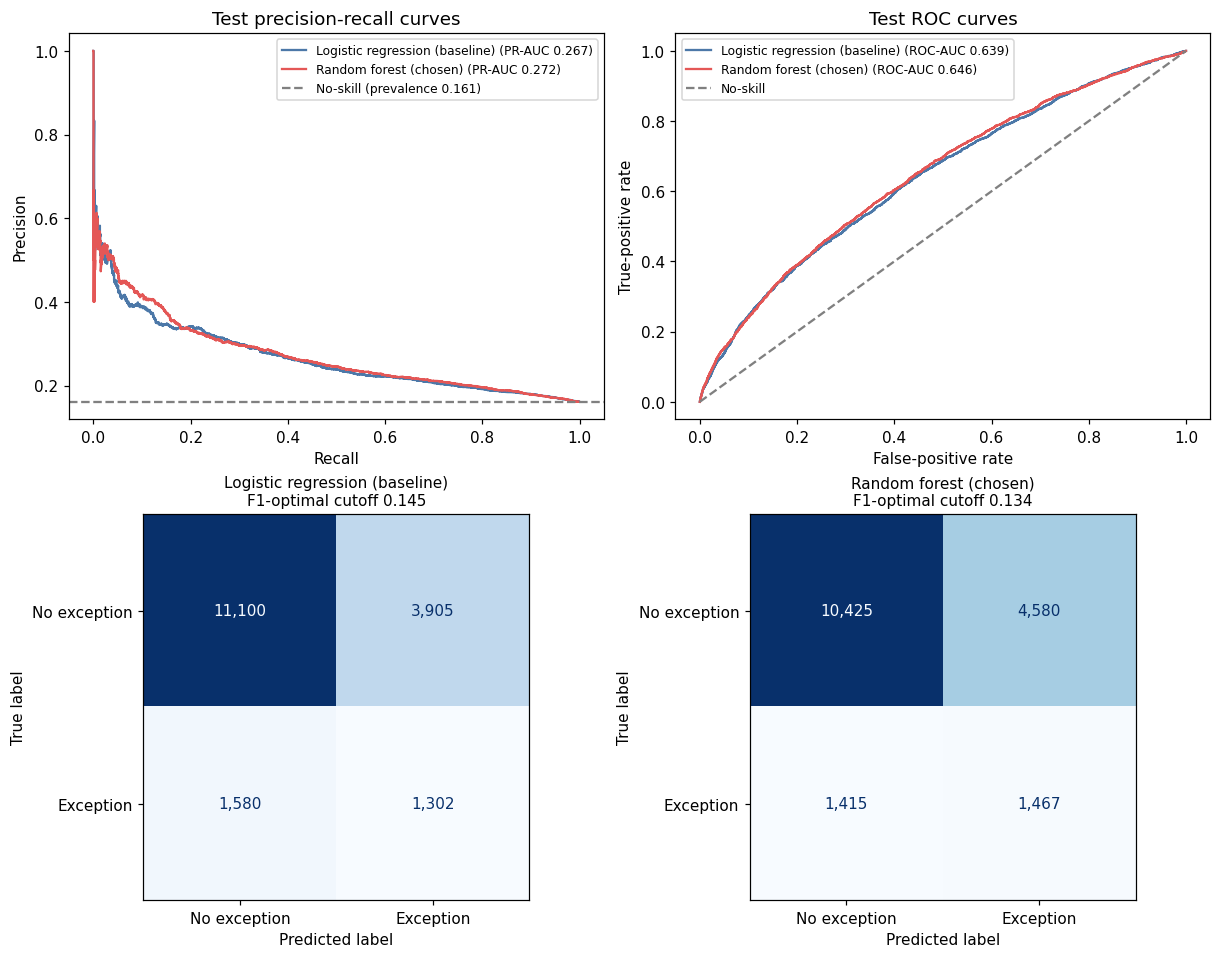

Exception rate  PR-AUC  ROC-AUC  \
Model                          Split                                         
Logistic regression (baseline) Train               0.1286  0.2254   0.6435   
                               Validation          0.1490  0.2562   0.6484   
                               Test                0.1611  0.2669   0.6394   
Random forest (chosen)         Train               0.1286  0.3285   0.6936   
                               Validation          0.1490  0.2654   0.6509   
                               Test                0.1611  0.2723   0.6456   

                                           Precision @cutoff  Recall @cutoff  \
Model                          Split                                           
Logistic regression (baseline) Train                  0.2045          0.4615   
                               Validation             0.2419          0.4823   
                               Test                   0.2500          0.4518   
Random forest (chosen)         Train                  0.2228          0.5833   
                               Validation             0.2288          0.5269   
                               Test                   0.2426          0.5090   

                                           F1 @cutoff  
Model                          Split                   
Logistic regression (baseline) Train           0.2834  
                               Validation      0.3222  
                               Test            0.3219  
Random forest (chosen)         Train           0.3225  
                               Validation      0.3190  
                               Test            0.3286

Cross-check (chosen forest, test): {'Spark areaUnderROC': 0.6456, 'Spark areaUnderPR': 0.2713, 'sklearn ROC-AUC': np.float64(0.6456), 'sklearn PR-AUC': np.float64(0.2723)}


In [12]:
test = clean_orders(parse_orders(orders.where("split = 'Test'")))
test_matrix = to_matrix(test, preprocess).cache()
test_scores = {name: score(model, test_matrix) for name, model in final_models.items()}   # the single test evaluation
prevalence = test_scores[FOREST]["label"].mean()
n_test = len(test_scores[FOREST])

rows = []
for name in (BASE, FOREST):
    sc = test_scores[name]; pr, roc = rank_metrics(sc)
    rows.append({"Model": name, **at_threshold(sc, CUTS[name][RULES[0]]), "ROC-AUC": roc, "PR-AUC": pr})
P_ = int(round(prevalence * n_test))
rows.append({"Model": "Always predict 'no exception' (reference)", "Threshold": np.inf, "Alerts": 0, "Alert rate": 0.0,
             "TN": n_test - P_, "FP": 0, "FN": P_, "TP": 0, "Precision": 0.0, "Recall": 0.0, "F1": 0.0,
             "Accuracy": 1 - prevalence, "Cost per 1,000 orders": 1000 * COST_FN * P_ / n_test, "ROC-AUC": 0.5, "PR-AUC": prevalence})
test_metrics = pd.DataFrame(rows).set_index("Model")
print(f"TEST set: {n_test:,} orders, exception rate {prevalence:.1%}")
display(save(test_metrics.round(4), "test_metrics"))

rows = []
for name in (BASE, FOREST):
    for rule, thr in CUTS[name].items():
        rows.append({"Model": name, "Rule": rule, **at_threshold(test_scores[name], thr)})
rows.append({"Model": "Reference", "Rule": "Alert nobody", **at_threshold(test_scores[FOREST], np.inf)})
rows.append({"Model": "Reference", "Rule": "Alert everybody", **at_threshold(test_scores[FOREST], -np.inf)})
test_rules = pd.DataFrame(rows).set_index(["Model", "Rule"])
display(save(test_rules.round(4), "test_cutoff_rules"))

fig, axes = plt.subplots(2, 2, figsize=(11, 8.6), layout="constrained")
for name, color in ((BASE, "#4C78A8"), (FOREST, "#E45756")):
    y, s = test_scores[name]["label"], test_scores[name]["score"]
    p, r, _ = precision_recall_curve(y, s); fpr, tpr, _ = roc_curve(y, s)
    axes[0, 0].plot(r, p, color=color, label=f"{name} (PR-AUC {pr_auc(y, s):.3f})")
    axes[0, 1].plot(fpr, tpr, color=color, label=f"{name} (ROC-AUC {roc_auc_score(y, s):.3f})")
axes[0, 0].axhline(prevalence, color="gray", linestyle="--", label=f"No-skill (prevalence {prevalence:.3f})")
axes[0, 0].set(xlabel="Recall", ylabel="Precision", title="Test precision-recall curves"); axes[0, 0].legend(fontsize=8)
axes[0, 1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="No-skill")
axes[0, 1].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Test ROC curves"); axes[0, 1].legend(fontsize=8)
for ax, name in zip(axes[1], (BASE, FOREST)):
    r = test_metrics.loc[name]
    cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]], dtype=int)
    ConfusionMatrixDisplay(cm, display_labels=["No exception", "Exception"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_title(f"{name}\nF1-optimal cutoff {r['Threshold']:.3f}", fontsize=10)
fig.savefig(OUT / "fig_test_evaluation.png")
plt.show()

# over/underfitting and drift: the same models on train, validation and test
rows = []
sets = {"Train": None, "Validation": None, "Test": None}
for name in (BASE, FOREST):
    for split, sc in (("Train", score(final_models[name], train_matrix)), ("Validation", val_scores[name]), ("Test", test_scores[name])):
        pr, roc = rank_metrics(sc); r = at_threshold(sc, CUTS[name][RULES[0]])
        rows.append({"Model": name, "Split": split, "Exception rate": sc["label"].mean(), "PR-AUC": pr, "ROC-AUC": roc,
                     "Precision @cutoff": r["Precision"], "Recall @cutoff": r["Recall"], "F1 @cutoff": r["F1"]})
by_split = pd.DataFrame(rows).set_index(["Model", "Split"])
display(save(by_split.round(4), "metrics_by_split"))

# Spark's own evaluator as a cross-check of the scikit-learn metrics (same ranking, slightly different PR-AUC integration)
pred = final_models[FOREST].transform(test_matrix)
ev = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction")
spark_check = {"Spark areaUnderROC": ev.setMetricName("areaUnderROC").evaluate(pred),
               "Spark areaUnderPR": ev.setMetricName("areaUnderPR").evaluate(pred),
               "sklearn ROC-AUC": test_metrics.loc[FOREST, "ROC-AUC"], "sklearn PR-AUC": test_metrics.loc[FOREST, "PR-AUC"]}
print("Cross-check (chosen forest, test):", {k: round(v, 4) for k, v in spark_check.items()})
RUN["spark_check"] = spark_check
RUN["test_prevalence"] = float(prevalence); RUN["test_orders"] = int(n_test)

### Is the forest really better than the baseline?

**Cell 24 resamples test customers 1,000 times** (customers repeat, so I resample them, not single orders) and recomputes both models on the same resamples.

- **Ranking quality: can’t tell them apart.** PR-AUC +0.005 (95% CI −0.003 to +0.014), ROC-AUC +0.006 (−0.001 to +0.013), F1 +0.007 (−0.003 to +0.016). All intervals include 0.
- **Recall is +5.7 points higher** for the forest (CI 4.2 to 7.3) while precision is −0.7 points. But that is mostly because its cutoff alerts on more orders (33.8% vs 29.1%), a different operating point, not a better model.

**Honest conclusion: the forest is at best marginally better, and I should not claim a clear win.**

In [13]:
cust = orders.where("split = 'Test'").select("order_id", "customer_id").toPandas()
bt = (test_scores[BASE].rename(columns={"score": "base"})
      .merge(test_scores[FOREST][["order_id", "score"]].rename(columns={"score": "forest"}), on="order_id")
      .merge(cust, on="order_id", how="left"))
codes, uniq = pd.factorize(bt["customer_id"].fillna(bt["order_id"]))
order_idx = np.argsort(codes, kind="stable"); counts = np.bincount(codes); starts = np.r_[0, np.cumsum(counts)]
y_all, b_all, f_all = bt["label"].to_numpy().astype(int), bt["base"].to_numpy(), bt["forest"].to_numpy()
tb, tf = CUTS[BASE][RULES[0]], CUTS[FOREST][RULES[0]]

def metric_set(y, s, thr):
    alert = s >= thr; tp = (alert & (y == 1)).sum(); fp = (alert & (y == 0)).sum(); fn = (~alert & (y == 1)).sum()
    return {"PR-AUC": pr_auc(y, s), "ROC-AUC": roc_auc_score(y, s), "Precision": tp / max(tp + fp, 1),
            "Recall": tp / max(tp + fn, 1), "F1": 2 * tp / max(2 * tp + fp + fn, 1)}

rng = np.random.default_rng(SEED)
boot = []
for _ in range(N_BOOT):
    pick = rng.integers(0, len(counts), len(counts))
    idx = np.concatenate([order_idx[starts[k]:starts[k + 1]] for k in pick])
    y = y_all[idx]
    mb, mf = metric_set(y, b_all[idx], tb), metric_set(y, f_all[idx], tf)
    boot.append({**{f"base {k}": v for k, v in mb.items()}, **{f"forest {k}": v for k, v in mf.items()},
                 **{f"diff {k}": mf[k] - mb[k] for k in mb}})
boot = pd.DataFrame(boot)
point_b, point_f = metric_set(y_all, b_all, tb), metric_set(y_all, f_all, tf)
rows = []
for k in point_b:
    lo, hi = boot[f"diff {k}"].quantile([0.025, 0.975])
    rows.append({"Metric": k, "Baseline": point_b[k], "Forest": point_f[k], "Forest - baseline": point_f[k] - point_b[k],
                 "95% CI low": lo, "95% CI high": hi, "Forest better in (% of resamples)": 100 * (boot[f"diff {k}"] > 0).mean(),
                 "Interval excludes 0": bool(lo > 0 or hi < 0)})
bootstrap = pd.DataFrame(rows).set_index("Metric")
print(f"Customer-level bootstrap, {N_BOOT} resamples of {len(counts):,} test customers")
display(save(bootstrap.round(4), "bootstrap_difference"))
own_ci = pd.DataFrame({m: {"PR-AUC 95% CI": f"{boot[f'{p} PR-AUC'].quantile(.025):.3f} to {boot[f'{p} PR-AUC'].quantile(.975):.3f}",
                           "ROC-AUC 95% CI": f"{boot[f'{p} ROC-AUC'].quantile(.025):.3f} to {boot[f'{p} ROC-AUC'].quantile(.975):.3f}",
                           "F1 95% CI": f"{boot[f'{p} F1'].quantile(.025):.3f} to {boot[f'{p} F1'].quantile(.975):.3f}"}
                       for m, p in ((BASE, "base"), (FOREST, "forest"))}).T
display(save(own_ci, "bootstrap_own_ci"))

Customer-level bootstrap, 1000 resamples of 14,797 test customers


,Baseline,Forest,Forest - baseline,95% CI low,95% CI high,Forest better in (% of resamples),Interval excludes 0
Metric,,,,,,,
PR-AUC,0.2669,0.2723,0.0054,-0.0033,0.0141,89.9,False
ROC-AUC,0.6394,0.6456,0.0062,-0.0005,0.0127,96.4,False
Precision,0.2500,0.2426,-0.0074,-0.0147,-0.0005,1.8,True
Recall,0.4518,0.5090,0.0573,0.0417,0.0729,100.0,True
F1,0.3219,0.3286,0.0067,-0.0025,0.0162,90.6,False


,PR-AUC 95% CI,ROC-AUC 95% CI,F1 95% CI
Logistic regression (baseline),0.253 to 0.282,0.629 to 0.651,0.309 to 0.336
Random forest (chosen),0.258 to 0.287,0.634 to 0.657,0.316 to 0.342


## 7. What did the model get wrong?

**Cell 26 looks at the forest’s errors three ways.**

1. **By group.** The model alerts mostly where risk factors pile up: **rural** zones (73% of orders alerted, recall 83%) and **storm** forecasts (70% alerted, recall 78%). It misses most in **express** service (recall only 36%) and in places with no obvious risk factor.
2. **Six extreme orders.** The three worst false alerts all had long distances or storm or snow forecasts but no exception. The three worst misses were *express*, *clear weather* and *short distance* orders that looked safe but had a problem.
3. **One order traced** from the raw CSV row, to the cleaned row, to its score and the alert decision. Good for explaining the pipeline.

**Cell 27 shows what drives the models.** The forest relies most on shipping distance, prior exception count, rural zones and address quality. Logistic regression raises risk for storm, rural and back-order-cleared orders and lowers it for express.

In plain terms: the errors are mostly orders whose problems the dispatch-time data cannot see.

In [14]:
thr = CUTS[FOREST][RULES[0]]
seg_cols = ["weather_forecast_at_dispatch", "shipping_service", "destination_zone"]
seg = test_scores[FOREST].merge(test.select("order_id", *seg_cols).toPandas(), on="order_id")
seg["alert"] = seg["score"] >= thr
tabs = []
for c in seg_cols:
    t = pd.DataFrame({"orders": seg.groupby(c).size(), "exception rate": seg.groupby(c)["label"].mean(),
                      "alert rate": seg.groupby(c)["alert"].mean(),
                      "recall": seg[seg["label"] == 1].groupby(c)["alert"].mean(),
                      "precision": seg[seg["alert"]].groupby(c)["label"].mean()})
    t.index = pd.MultiIndex.from_product([[c], t.index], names=["field", "value"]); tabs.append(t)
segments = pd.concat(tabs)
display(save(segments.round(3), "error_segments"))

scored = test_scores[FOREST]
alerts = scored["score"] >= thr
examples = pd.concat([
    scored[scored["label"].eq(0) & alerts].nlargest(3, "score").assign(error="False positive"),
    scored[scored["label"].eq(1) & ~alerts].nsmallest(3, "score").assign(error="False negative"),
])
fields = [DATE, "carrier", "shipping_service", "weather_forecast_at_dispatch", "shipping_distance_km", "promised_delivery_days"]
details = test.where(F.col("order_id").isin(examples["order_id"].tolist())).select("order_id", *fields)
ex = examples.merge(details.toPandas(), on="order_id").round({"score": 4})
display(save(ex.set_index("order_id"), "error_examples"))

oid = ex.iloc[0]["order_id"]
print(f"\nTracing one record: {oid}")
print("\n1) Raw CSV row (dispatch-time fields only; the outcome fields are hidden):")
display(raw.where(F.col("order_id") == oid).select(*[c for c in raw.columns if c not in POST_DISPATCH + [TARGET]]).toPandas().T.rename(columns=lambda i: "raw value"))
print("2) After cleaning (+ engineered features):")
display(test.where(F.col("order_id") == oid).toPandas().T.rename(columns=lambda i: "cleaned value"))
print("3) Scores and decisions:")
for name in (BASE, FOREST):
    s = float(test_scores[name].set_index("order_id").loc[oid, "score"]); cut = CUTS[name][RULES[0]]
    print(f"   {name}: score {s:.4f}, cutoff {cut:.4f} -> {'ALERT' if s >= cut else 'no alert'}; true label {int(test_scores[name].set_index('order_id').loc[oid, 'label'])}")

orders  exception rate  \
field                        value                                            
weather_forecast_at_dispatch __missing_or_unknown__     847           0.149   
                             clear                     8917           0.155   
                             rain                      3803           0.151   
                             snow                      1941           0.176   
                             storm                      852           0.266   
                             unknown                   1527           0.149   
shipping_service             economy                   4637           0.206   
                             express                   3214           0.125   
                             sameday                    722           0.145   
                             standard                  9314           0.152   
destination_zone             __missing_or_unknown__     279           0.168   
                             rural                     2612           0.229   
                             suburban                  6701           0.147   
                             urban                     8295           0.151   

                                                     alert rate  recall  \
field                        value                                        
weather_forecast_at_dispatch __missing_or_unknown__       0.326   0.476   
                             clear                        0.299   0.465   
                             rain                         0.336   0.498   
                             snow                         0.384   0.551   
                             storm                        0.697   0.775   
                             unknown                      0.322   0.491   
shipping_service             economy                      0.513   0.671   
                             express                      0.231   0.355   
                             sameday                      0.276   0.400   
                             standard                     0.293   0.452   
destination_zone             __missing_or_unknown__       0.226   0.255   
                             rural                        0.734   0.831   
                             suburban                     0.268   0.432   
                             urban                        0.274   0.426   

                                                     precision  
field                        value                              
weather_forecast_at_dispatch __missing_or_unknown__      0.217  
                             clear                       0.242  
                             rain                        0.224  
                             snow                        0.252  
                             storm                       0.296  
                             unknown                     0.228  
shipping_service             economy                     0.269  
                             express                     0.193  
                             sameday                     0.211  
                             standard                    0.235  
destination_zone             __missing_or_unknown__      0.190  
                             rural                       0.259  
                             suburban                    0.237  
                             urban                       0.234

,label,score,error,dispatch_date,carrier,shipping_service,weather_forecast_at_dispatch,shipping_distance_km,promised_delivery_days
order_id,,,,,,,,,
ORD-1080450,0.0,0.4874,False positive,2026-06-14,parcelnorth,express,rain,1517.5,6.0
ORD-1094401,0.0,0.4712,False positive,2026-04-04,urbanxpress,express,snow,1449.2,5.0
ORD-1115316,0.0,0.4706,False positive,2026-06-14,parcelnorth,economy,storm,456.2,6.0
ORD-1021050,1.0,0.0726,False negative,2026-05-15,parcelnorth,express,clear,134.7,6.0
ORD-1089867,1.0,0.0726,False negative,2026-04-28,mapleship,express,clear,193.5,2.0
ORD-1047397,1.0,0.0728,False negative,2026-03-20,parcelnorth,express,clear,212.6,3.0



Tracing one record: ORD-1080450

1) Raw CSV row (dispatch-time fields only; the outcome fields are hidden):


,raw value
order_id,ORD-1080450
customer_id,C30575
merchant_id,M231
dispatch_date,2026-06-14
warehouse_id,WH-TOR
destination_province,QC
destination_zone,Rural
carrier,ParcelNorth
shipping_service,Express
order_channel,Website


2) After cleaning (+ engineered features):


,cleaned value
order_id,ORD-1080450
dispatch_date,2026-06-14
label,0.0
order_value_cad,16.39
parcel_weight_kg,1.39
item_count,5.0
shipping_distance_km,1517.5
customer_tenure_months,36.0
prior_order_count,20.0
prior_exception_count,3.0


3) Scores and decisions:
   Logistic regression (baseline): score 0.4593, cutoff 0.1451 -> ALERT; true label 0
   Random forest (chosen): score 0.4874, cutoff 0.1344 -> ALERT; true label 0


In [15]:
# What drives the models? (feature names rebuilt from the fitted pipeline)
idx_model = preprocess.stages[1]
names = list(numeric)
for c, labels in zip(categories, idx_model.labelsArray):
    names += [f"{c}={l}" for l in labels] + [f"{c}=<unseen>"]
assert len(names) == final_models[FOREST].numFeatures == final_models[BASE].numFeatures
imp = pd.Series(final_models[FOREST].featureImportances.toArray(), index=names).sort_values(ascending=False)
coef = pd.Series(final_models[BASE].coefficients.toArray(), index=names)
print("Random forest: 12 most important inputs (importances sum to 1)")
display(save(imp.head(12).round(4).to_frame("importance"), "forest_importance"))
cat_coef = coef[[n for n in names if n not in numeric]]
print("Logistic regression: categorical inputs that raise / lower the log-odds most (numeric coefficients depend on units, so they are not ranked)")
display(save(pd.concat([cat_coef.nlargest(6), cat_coef.nsmallest(6)]).round(3).to_frame("coefficient"), "lr_coefficients"))

Random forest: 12 most important inputs (importances sum to 1)


,importance
shipping_distance_km,0.1525
prior_exception_count,0.1269
destination_zone=rural,0.0700
address_quality_score,0.0655
warehouse_backlog_at_dispatch,0.0540
distance_per_promised_day,0.0516
shipping_service=economy,0.0416
weather_forecast_at_dispatch=storm,0.0413
order_value_cad,0.0383
pre_dispatch_prep_hours,0.0374


Logistic regression: categorical inputs that raise / lower the log-odds most (numeric coefficients depend on units, so they are not ranked)


,coefficient
weather_forecast_at_dispatch=storm,0.670
destination_zone=rural,0.544
inventory_status_at_dispatch=backordercleared,0.416
shipping_service=economy,0.327
carrier=coast2coast,0.283
weather_forecast_at_dispatch=snow,0.243
shipping_service=express,-0.205
inventory_status_at_dispatch=instock,-0.066
dispatch_weekday=Tue,-0.051
destination_province=mb,-0.044


## 8. Data-quality log

**Cell 29 prints the full log**, one row per problem with the detection evidence, the action, why I did it, and the possible effect on results. It is also saved as `outputs/data_quality_log.csv`.

In [16]:
dq = pd.DataFrame(dq_rows)
dq.index = dq.index + 1; dq.index.name = "#"
display(save(dq, "data_quality_log"))
dq_md = ["| # | Problem | Detection evidence | Action | Rationale | Potential effect | Scope | Count |", "|---|---|---|---|---|---|---|---|"]
for i, r in dq.iterrows():
    dq_md.append("| " + " | ".join([str(i)] + [str(r[c]).replace("|", "/") for c in dq.columns]) + " |")
(OUT / "data_quality_log.md").write_text("\n".join(dq_md))

RUN.update({"distinct_rows": int(distinct_count), "conflict_ids": int(conflict_ids), "conflict_rows": int(conflict_rows),
            "eligible_orders": int(eligible_count), "split_orders": {k: int(v) for k, v in splits["orders"].items()},
            "exception_rate_train": float(balance.loc["Train", "exception rate (%)"]),
            "exception_rate_validation": float(balance.loc["Validation", "exception rate (%)"]),
            "runtime_minutes": round((time.time() - T0) / 60, 1)})
(OUT / "run_record.json").write_text(json.dumps(RUN, indent=2, default=str))
print(f"Saved tables, figures and run_record.json to {OUT.resolve()} (runtime {RUN['runtime_minutes']} min)")
spark.stop()

,Problem,Detection evidence,Action,Rationale,Potential effect on results,Scope,Count
#,,,,,,,
1,Exact duplicate rows,"121,150 rows vs 120,650 after dropDuplicates()",Keep one copy of each exact duplicate.,The same order must not be counted twice or appear in two splits.,Negligible: identical rows carry no extra information.,Whole file,500
2,Same order_id with conflicting values,"650 order IDs have two different versions; they differ only in {'address_quality_score': 605, 'warehouse_backlog_at_dispatch': 650}. Exception rate of the conflicting rows 14.8% vs 13.7% overall.","Drop all 1,300 rows of these orders.",There is no authoritative copy; choosing one would inject arbitrary noise into two model inputs.,"Loses about 1% of orders. The exception rate of the dropped orders is close to the overall rate, so little bias is expected.",Whole file,650
3,Unusable dispatch date,Blank or non-ISO strings after removing duplicates: '' x198; '2025/13/09' x182; 'not_a_date' x168,Drop these rows.,"A chronological split needs a valid dispatch date. The text values are not dates ('2025/13/09' has month 13), so they cannot be repaired.",Loses under 0.5% of orders; unlikely to bias results.,Whole file,548
4,Missing or unreadable numbers,"Blank or unparsable cells per column: {'order_value_cad': 1381, 'parcel_weight_kg': 3255, 'shipping_distance_km': 2225, 'customer_tenure_months': 2192, 'address_quality_score': 6394}",Mark as missing; fill with the TRAINING median inside the fitted pipeline.,"The median is robust to the extreme values below, and learning it from training data only avoids leakage.",Imputation shrinks variation; missing-ness itself might carry signal (tested with flags in section 5).,Training split,15447
5,Impossible values and sentinel spikes,"Invalid per column: {'order_value_cad': 257, 'parcel_weight_kg': 547, 'shipping_distance_km': 408, 'address_quality_score': 574, 'pre_dispatch_prep_hours': 565, 'promised_delivery_days': 331}. Spi...",Mark as missing (then impute as above).,"Sentinels such as 999 kg sit far outside the realistic range, so they are data-entry codes, not genuine parcels.",A genuine extreme order could be lost; the flagged share per column is small.,Training split,2682
6,Inconsistent category spellings and unknown labels,Province repairs: 516; shipping-service repairs: 749; labels outside the known list (for example 'UNKNOWN') are treated as unknown.,"Lower-case, trim, map aliases (Ontario/ON, Std/Standard ...) to one value.",Spelling variants would otherwise split one real category into several sparse ones.,Cleaner categories; a few distinct raw labels are merged.,Training split,1265
7,Blank or unknown categories,"Blanks per column: {'destination_province': 133, 'destination_zone': 1441, 'order_channel': 1908, 'inventory_status_at_dispatch': 1466, 'weather_forecast_at_dispatch': 3719}. The weather field als...",Keep as an explicit 'missing or unknown' category.,Keeps the order in the data; the model can learn that unknown fields behave differently.,If blanks are random this adds a little noise.,Training split,8667
8,Inconsistent history and weekend flag,prior_exception_count > prior_order_count: 0 rows; weekend_dispatch disagrees with the date: 0 rows.,No repair needed (rule kept in code in case of future files); weekday is derived from the date and the redundant flag is not used.,A checked rule that found nothing is evidence the fields are consistent.,None observed.,Training split,0
9,Post-dispatch columns (target leakage),actual_delivery_days: AUC 0.87; delivery_attempts_total: AUC 0.77; refund_issued_after_dispatch: AUC 0.73; post_delivery_support_tickets: AUC 0.90; final_delivery_status is almost a copy of the la...,Exclude all five from the model inputs (asserted in code).,"They are only known after dispatch, so they cannot be used at prediction time even though they are highly predictive.",Prevents an unrealistically high score. Reported accuracy is lower but honest.,Whole file,5


Saved tables, figures and run_record.json to /tmp/run/outputs (runtime 27.1 min)


## What are ways to improve this model?

- **The signal is weak.** ROC-AUC is about 0.64 for both models. More dispatch-time information (carrier or lane performance history, real-time warehouse load) would help more than a fancier model.
- **Don’t over-claim the forest.** The bootstrap says its ranking is not clearly better than logistic regression. Its real difference is that it alerts on more orders.
- **Get the costs from the business.** The best cutoff depends on what a check costs and what an intervention achieves. The cost rule changes a lot between 2× and 10×.
- **Calibrate the scores** before reading them as probabilities.
- **Watch for drift.** The exception rate rose from 12.9% to 16.1%. Retrain regularly and monitor it.
- **Limits of this study.** One future period of synthetic data; returning customers included; no label timestamps, so final seven-day outcomes are assumed complete; prior-order counts assumed to be dispatch-time snapshots.